In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report


In [3]:
df = pd.read_csv("./data/diabetes_clean.csv")
df.head()

,pregnancies,glucose,diastolic,triceps,insulin,bmi,dpf,age,diabetes
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


# Data Preprocessing

In [3]:
df.shape

(768, 9)

In [5]:
df["diabetes"].value_counts()

diabetes
0    500
1    268
Name: count, dtype: int64

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   pregnancies  768 non-null    int64  
 1   glucose      768 non-null    int64  
 2   diastolic    768 non-null    int64  
 3   triceps      768 non-null    int64  
 4   insulin      768 non-null    int64  
 5   bmi          768 non-null    float64
 6   dpf          768 non-null    float64
 7   age          768 non-null    int64  
 8   diabetes     768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [7]:
df.isnull().sum()

pregnancies    0
glucose        0
diastolic      0
triceps        0
insulin        0
bmi            0
dpf            0
age            0
diabetes       0
dtype: int64

In [11]:
df.describe(include='all')

,pregnancies,glucose,diastolic,triceps,insulin,bmi,dpf,age,diabetes
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


# Data Visualization

In [12]:
sns.set()

<Axes: xlabel='pregnancies', ylabel='count'>

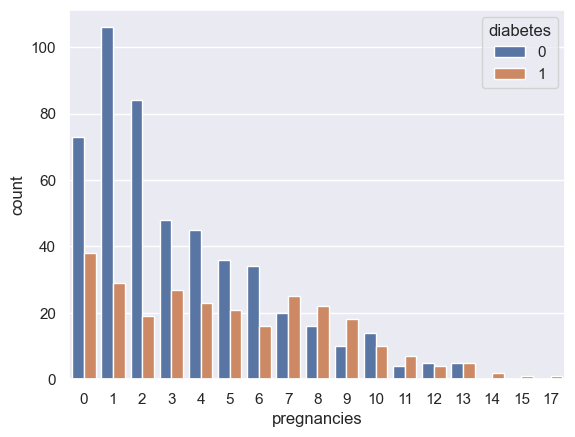

In [30]:
sns.countplot(x="pregnancies", hue="diabetes", data=df)

<Axes: xlabel='diabetes', ylabel='count'>

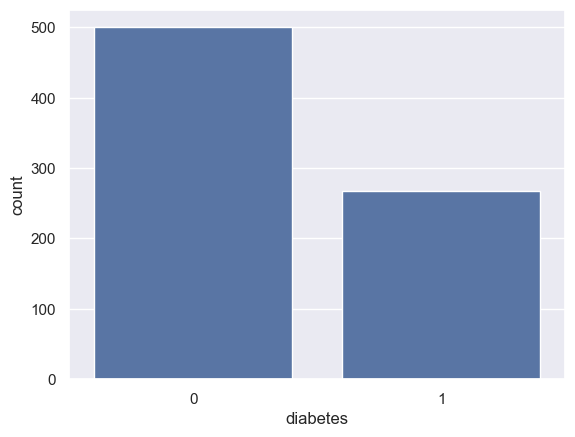

In [31]:
sns.countplot(x="diabetes", data=df)

In [32]:
df.head()

,pregnancies,glucose,diastolic,triceps,insulin,bmi,dpf,age,diabetes
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


# Training Data

In [129]:
X = df.drop("diabetes", axis=1)
y = df["diabetes"]

In [130]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

In [131]:
X_train.head()

,pregnancies,glucose,diastolic,triceps,insulin,bmi,dpf,age
209,7,184,84,33,0,35.5,0.355,41
176,6,85,78,0,0,31.2,0.382,42
147,2,106,64,35,119,30.5,1.400,34
454,2,100,54,28,105,37.8,0.498,24
636,5,104,74,0,0,28.8,0.153,48


In [132]:
THRESHOLD = 0.65

# K Neighbor

In [56]:
from sklearn.neighbors import KNeighborsClassifier
import time

In [44]:
knn = KNeighborsClassifier()
knn.fit(X_train, y_train)
knn

KNeighborsClassifier()

In [91]:
start_pred = time.time()
y_proba = knn.predict_proba(X_test)[:,1]
y_pred = (y_proba >= THRESHOLD).astype(int)
pred_time = time.time() - start_pred

print(f"⏱ Prediction time: {pred_time:.4f} seconds")

⏱ Prediction time: 0.0070 seconds


In [92]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.73      0.94      0.82       150
           1       0.76      0.35      0.47        81

    accuracy                           0.73       231
   macro avg       0.74      0.64      0.65       231
weighted avg       0.74      0.73      0.70       231



# NaiveBayes

In [47]:
from sklearn.naive_bayes import GaussianNB

In [48]:
nb_model = GaussianNB()
nb_model = nb_model.fit(X_train, y_train)
nb_model

GaussianNB()

In [93]:
start_pred = time.time()
y_proba = nb_model.predict_proba(X_test)[:,1]
y_pred = (y_proba >= THRESHOLD).astype(int)
pred_time = time.time() - start_pred

print(f"⏱ Prediction time: {pred_time:.4f} seconds")


⏱ Prediction time: 0.0050 seconds


In [94]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.76      0.87      0.81       150
           1       0.67      0.49      0.57        81

    accuracy                           0.74       231
   macro avg       0.71      0.68      0.69       231
weighted avg       0.73      0.74      0.72       231



# SVM

In [51]:
from sklearn.svm import SVC

In [53]:
svm = SVC()
svm.fit(X_train, y_train)
svm

SVC()

In [86]:
start_pred = time.time()
y_pred = svm.predict(X_test)
pred_time = time.time() - start_pred

print(f"⏱ Prediction time: {pred_time:.4f} seconds")


⏱ Prediction time: 0.0230 seconds


In [87]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.75      0.91      0.82       150
           1       0.72      0.44      0.55        81

    accuracy                           0.74       231
   macro avg       0.74      0.68      0.69       231
weighted avg       0.74      0.74      0.73       231



# Logistic Regression

In [147]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

In [148]:
log = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(max_iter=1000))
])


# log = LogisticRegression(max_iter=1000)
log.fit(X_train, y_train)
log

Pipeline(steps=[('scaler', StandardScaler()),
                ('logistic', LogisticRegression(max_iter=1000))])

In [149]:
start_pred = time.time()
y_proba = log.predict_proba(X_test)[:,1]
y_pred = (y_proba >= THRESHOLD).astype(int)
pred_time = time.time() - start_pred

print(f"⏱ Prediction time: {pred_time:.4f} seconds")


⏱ Prediction time: 0.0050 seconds


In [150]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.74      0.94      0.83       150
           1       0.78      0.38      0.51        81

    accuracy                           0.74       231
   macro avg       0.76      0.66      0.67       231
weighted avg       0.75      0.74      0.72       231



# RandomForestClassifier

In [101]:
from sklearn.ensemble import RandomForestClassifier

In [103]:
rf = RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42, n_jobs=1)
rf.fit(X_train, y_train)
rf

RandomForestClassifier(class_weight='balanced', n_estimators=300, n_jobs=1,
                       random_state=42)

In [104]:
start_pred = time.time()
y_proba = rf.predict_proba(X_test)[:,1]
y_pred = (y_proba >= THRESHOLD).astype(int)
pred_time = time.time() - start_pred

print(f"⏱ Prediction time: {pred_time:.4f} seconds")


⏱ Prediction time: 0.0420 seconds


In [105]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.72      0.94      0.82       150
           1       0.75      0.33      0.46        81

    accuracy                           0.73       231
   macro avg       0.74      0.64      0.64       231
weighted avg       0.73      0.73      0.69       231



ML Model Choice 
- Logistic Regression
- It is one of the model that has a hight accuarcy of 0.74

# Threshold boosting for LogisticRegression

In [142]:
from sklearn.metrics import precision_score, recall_score, accuracy_score, f1_score

In [165]:
proba = log.predict_proba(X_test)[:,1]

print(f"{'Thresh':<8}{'Acc_1':<8} {'Prec_1':<8}{'Rec_1':<8}{'F1_1':<8}")
for thresh in [0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60, 0.65, 0.70]: 
    preds = (proba >= thresh).astype(int)
    acc = accuracy_score(y_test, preds)
    rec = recall_score(y_test, preds)
    prec = precision_score(y_test, preds)
    f1 = f1_score(y_test, preds)
    print(f"{thresh:<8}{acc:<8.3f}{prec:<8.3f}{rec:<8.3f}{f1:<8.3f}")

Thresh  Acc_1    Prec_1  Rec_1   F1_1    
0.25    0.745   0.593   0.864   0.704   
0.3     0.762   0.625   0.802   0.703   
0.35    0.762   0.648   0.704   0.675   
0.4     0.766   0.671   0.654   0.662   
0.45    0.736   0.643   0.556   0.596   
0.5     0.745   0.677   0.519   0.587   
0.55    0.745   0.696   0.481   0.569   
0.6     0.740   0.714   0.432   0.538   
0.65    0.745   0.775   0.383   0.512   
0.7     0.732   0.771   0.333   0.466   


- Accuracy = How many predictions did my model get correct overall?
- Precision = When my model predicts true positive, how often is it actually correct?
- Recall = Of all true positives, how many did my model successfully identify?

The best threshold is 0.40